<a href="https://colab.research.google.com/github/sharmaaviraj/Deep-Learning-Assignment-Reports/blob/main/Deep_Learning_Lab_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 4: Simple RNN for Sentiment Analysis

**Name:** Aviraj Sharma

**SAP ID:** 590016470

**Batch:** 24

**Subject:** Deep Learning

## 1. Aim

To implement a Simple Recurrent Neural Network (RNN) using PyTorch for sentiment analysis and classify text sentences as positive or negative.

## 2. Objectives

- To understand the working of a Simple RNN.
- To preprocess text and convert words into numerical representations.
- To train an RNN model using labelled sentiment data.
- To predict the sentiment of given sentences.
- To visualize the training loss over multiple epochs.

In [1]:

from pathlib import Path
import re
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt

EPOCHS = 30
LEARNING_RATE = 0.01

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)


Device: cpu


## 3. Importing Required Libraries

The required Python libraries are imported to implement and train the RNN model.

- **PyTorch:** Used to build and train the neural network.
- **torch.nn:** Provides neural network layers and loss functions.
- **DataLoader and Dataset:** Used to manage and load the dataset in batches.
- **Matplotlib:** Used to visualize the training loss.
- **Path and re:** Used for file handling and text preprocessing.

The program also checks whether a GPU is available and selects the appropriate computing device.

In [2]:

SAMPLES = [
    ("i love this movie", 1),
    ("this film is amazing", 1),
    ("what a wonderful story", 1),
    ("i enjoyed the acting", 1),
    ("this movie is excellent", 1),
    ("the film was really good", 1),

    ("i hate this movie", 0),
    ("this film is terrible", 0),
    ("what a boring story", 0),
    ("i disliked the acting", 0),
    ("this movie is awful", 0),
    ("the film was really bad", 0),
]

def words(text):
    return re.findall(r"[a-z]+", text.lower())

print("Total samples:", len(SAMPLES))
print("Positive samples:", sum(label for _, label in SAMPLES))
print("Negative samples:", sum(1 for _, label in SAMPLES if label == 0))


Total samples: 12
Positive samples: 6
Negative samples: 6


## 4. Dataset Creation

A small, built-in dataset is created for sentiment classification. It contains 12 sentences, including six positive and six negative examples.

Each sentence is associated with a numerical label:

- **1:** Positive sentiment
- **0:** Negative sentiment

Examples of positive sentences include "i love this movie" and "this film is amazing". Negative examples include "i hate this movie" and "this film is terrible".

Using a built-in dataset avoids the need to download external files.

In [3]:

vocab = {"<PAD>": 0, "<UNK>": 1}

for sentence, _ in SAMPLES:
    for word in words(sentence):
        if word not in vocab:
            vocab[word] = len(vocab)

MAX_LENGTH = max(len(words(sentence)) for sentence, _ in SAMPLES)

def encode(sentence):
    ids = [vocab.get(word, 1) for word in words(sentence)]
    ids = ids[:MAX_LENGTH]
    return ids + [0] * (MAX_LENGTH - len(ids))

print("Vocabulary size:", len(vocab))
print("Maximum sentence length:", MAX_LENGTH)
print("Encoded example:", encode("i love this movie"))


Vocabulary size: 26
Maximum sentence length: 5
Encoded example: [2, 3, 4, 5, 0]


## 5. Text Preprocessing and Vocabulary Creation

Neural networks cannot directly process raw text, so the sentences must be converted into numerical sequences.

The following operations are performed:

1. Convert all text to lowercase.
2. Extract individual words using regular expressions.
3. Create a vocabulary and assign a unique integer ID to each word.
4. Reserve ID 0 for padding (PAD) and ID 1 for unknown words (UNK).
5. Convert each sentence into a sequence of word IDs.
6. Pad shorter sentences with zeros to obtain a fixed sequence length.

This process makes the text suitable for input to the RNN model.

In [4]:

class SentimentDataset(Dataset):

    def __len__(self):
        return len(SAMPLES)

    def __getitem__(self, index):
        sentence, label = SAMPLES[index]

        return (
            torch.tensor(encode(sentence), dtype=torch.long),
            torch.tensor(label, dtype=torch.long)
        )

dataset = SentimentDataset()

print("Dataset size:", len(dataset))
print("First sentence IDs:", dataset[0][0])
print("First label:", dataset[0][1].item())


Dataset size: 12
First sentence IDs: tensor([2, 3, 4, 5, 0])
First label: 1


## 6. Creating the Dataset

A custom PyTorch Dataset class named SentimentDataset is defined to manage the preprocessed sentences and their corresponding labels.

The __len__() method returns the total number of samples, while the __getitem__() method retrieves a sentence and its sentiment label at a given index.

Both the encoded sentence and label are converted into PyTorch tensors. These tensors are used during model training.

In [5]:

class SimpleRNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=len(vocab),
            embedding_dim=16,
            padding_idx=0
        )

        self.rnn = nn.RNN(
            input_size=16,
            hidden_size=32,
            batch_first=True
        )

        self.output = nn.Linear(32, 2)

    def forward(self, text):
        embedded = self.embedding(text)

        _, hidden = self.rnn(embedded)

        logits = self.output(hidden[-1])

        return logits

model = SimpleRNN().to(device)

print(model)


SimpleRNN(
  (embedding): Embedding(26, 16, padding_idx=0)
  (rnn): RNN(16, 32, batch_first=True)
  (output): Linear(in_features=32, out_features=2, bias=True)
)


## 7. Building the Simple RNN Model

A neural network class named SimpleRNN is created using PyTorch.

The model consists of three main layers:

1. **Embedding Layer:** Converts word IDs into dense vectors of dimension 16.
2. **Simple RNN Layer:** Processes the sequence using 32 hidden units and maintains information from previous words.
3. **Fully Connected Layer:** Produces two output scores corresponding to positive and negative sentiment.

The final hidden state of the RNN is passed to the output layer to predict the sentiment class.

The batch_first=True parameter allows the input to be represented in the form (batch size, sequence length, embedding dimension).

In [6]:

loader = DataLoader(
    dataset,
    batch_size=4,
    shuffle=True
)

loss_function = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

losses = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for text, labels in loader:
        text = text.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        predictions = model(text)
        loss = loss_function(predictions, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(loader)
    losses.append(average_loss)

    if epoch == 0 or (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch + 1}/{EPOCHS} "
            f"- Loss: {average_loss:.4f}"
        )

print("Training complete.")


Epoch 1/30 - Loss: 0.8016
Epoch 5/30 - Loss: 0.3177
Epoch 10/30 - Loss: 0.0069
Epoch 15/30 - Loss: 0.0008
Epoch 20/30 - Loss: 0.0004
Epoch 25/30 - Loss: 0.0004
Epoch 30/30 - Loss: 0.0003
Training complete.


## 8. Training the Model

The model is trained using the prepared dataset for 30 epochs with a batch size of 4.

The training process uses the following configuration:

- **Optimizer:** Adam
- **Learning Rate:** 0.01
- **Loss Function:** Cross-Entropy Loss
- **Epochs:** 30
- **Batch Size:** 4

For each batch, the model generates predictions, calculates the loss, computes gradients using backpropagation, and updates its parameters using the optimizer.

The average loss for each epoch is recorded and displayed at regular intervals. A decreasing loss generally indicates that the model is learning from the training data.

## 9. Model Evaluation and Sentiment Prediction

After training, the model is switched to evaluation mode using model.eval(). The torch.no_grad() context disables gradient calculations during evaluation.

First, the model predicts labels for the training dataset, and the training accuracy is calculated by comparing predicted labels with actual labels.

Next, the model is tested on sample sentences. The output class with the highest score is selected as the predicted sentiment.

Example predictions may include:

- "i love this film" → Positive
- "this movie is boring" → Negative

Since the dataset is very small, the calculated accuracy represents performance on the training data and should not be interpreted as a measure of real-world generalization.

In [7]:

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for text, labels in DataLoader(dataset, batch_size=4):
        text = text.to(device)
        labels = labels.to(device)

        outputs = model(text)
        predicted = outputs.argmax(dim=1)

        correct += (predicted == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total

print(f"Training Dataset Accuracy: {accuracy:.2f}%")

examples = [
    "i love this film",
    "this movie is boring",
    "this movie is excellent",
    "the film was terrible"
]

print("\nExample predictions:")

with torch.no_grad():
    for sentence in examples:
        x = torch.tensor(
            [encode(sentence)],
            dtype=torch.long
        ).to(device)

        prediction = model(x).argmax(dim=1).item()

        sentiment = "Positive" if prediction == 1 else "Negative"

        print(f'"{sentence}" -> {sentiment}')


Training Dataset Accuracy: 100.00%

Example predictions:
"i love this film" -> Positive
"this movie is boring" -> Positive
"this movie is excellent" -> Positive
"the film was terrible" -> Negative


## 10. Training Loss Visualization

The training loss is plotted against the number of epochs using Matplotlib.

- **X-axis:** Number of training epochs.
- **Y-axis:** Average training loss.

The graph helps visualize how the loss changes during training. A downward trend indicates that the model is fitting the training dataset.

The generated graph can also be saved as an image for inclusion in the final practical report.



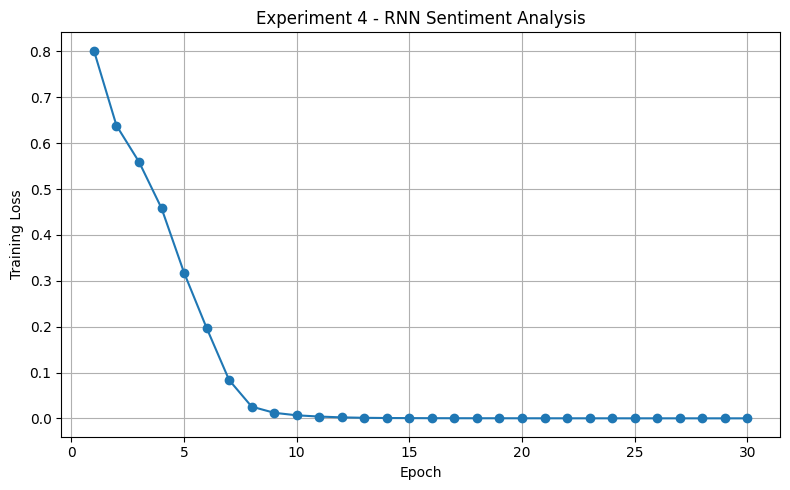

In [8]:

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Experiment 4 - RNN Sentiment Analysis")
plt.grid(True)
plt.tight_layout()
plt.show()


## 11. Saving the Model and Results

After training and testing, the program creates an output directory named outputs.

The following files are saved:

1. **rnn_sentiment_model.pt:** Contains the trained model parameters.
2. **loss_graph.png:** Contains the training loss graph.
3. **results.txt:** Contains the predicted sentiments of the example sentences.

Saving these files allows the trained model and experimental results to be accessed later without repeating the entire process.

In [9]:

output = Path("/content/outputs")
output.mkdir(exist_ok=True)

# Save trained model
torch.save(
    model.state_dict(),
    output / "rnn_sentiment_model.pt"
)

# Save loss graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Experiment 4 - RNN Sentiment Analysis")
plt.grid(True)
plt.tight_layout()
plt.savefig(output / "loss_graph.png")
plt.close()

# Save predictions
with torch.no_grad():
    result_lines = []

    for sentence in examples:
        x = torch.tensor(
            [encode(sentence)],
            dtype=torch.long
        ).to(device)

        prediction = model(x).argmax(dim=1).item()
        sentiment = "Positive" if prediction == 1 else "Negative"

        result_lines.append(f"{sentence} -> {sentiment}")

(output / "results.txt").write_text(
    "\n".join(result_lines) + "\n",
    encoding="utf-8"
)

print("Files saved in:", output)
print("Generated files:")
for file in output.iterdir():
    print(file.name)


Files saved in: /content/outputs
Generated files:
loss_graph.png
results.txt
rnn_sentiment_model.pt


## 12. Conclusion

In this experiment, a Simple Recurrent Neural Network was implemented using PyTorch to perform sentiment analysis. The text data was preprocessed, converted into numerical sequences, and used to train the model.

The trained model classified sample sentences as positive or negative, and the training loss was visualized using a graph. The experiment demonstrates the basic application of recurrent neural networks in Natural Language Processing.

**Limitation:** The model uses only 12 training sentences. Therefore, its predictions may not be reliable for complex or unseen text. A larger and more diverse dataset would be needed to evaluate its practical performance.

In [10]:

from google.colab import files

files.download("/content/outputs/rnn_sentiment_model.pt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:

from google.colab import files

files.download("/content/outputs/loss_graph.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

from google.colab import files

files.download("/content/outputs/results.txt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>